Build and evaluate a for predicting passenger survival using the Titanic dataset. Split the dataset into:
Perform on the training dataset.
Train the final Decision Tree model using the .
Evaluate the final model .
Report the following classification metrics:

Use relevant attributes such as:
- Pclass
- Sex
- Age
- SibSp
- Parch
- Fare
- Embarked

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.0k/22.0k [00:00<00:00, 23.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yasserh/titanic-dataset/versions/1


In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(path + "/Titanic-Dataset.csv")
df = df[['Pclass', 'Age', 'Sex', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Survived']]
df

,Pclass,Age,Sex,SibSp,Parch,Fare,Embarked,Survived
0,3,22.0,male,1,0,7.2500,S,0
1,1,38.0,female,1,0,71.2833,C,1
2,3,26.0,female,0,0,7.9250,S,1
3,1,35.0,female,1,0,53.1000,S,1
4,3,35.0,male,0,0,8.0500,S,0
...,...,...,...,...,...,...,...,...
886,2,27.0,male,0,0,13.0000,S,0
887,1,19.0,female,0,0,30.0000,S,1
888,3,NaN,female,1,2,23.4500,S,0
889,1,26.0,male,0,0,30.0000,C,1


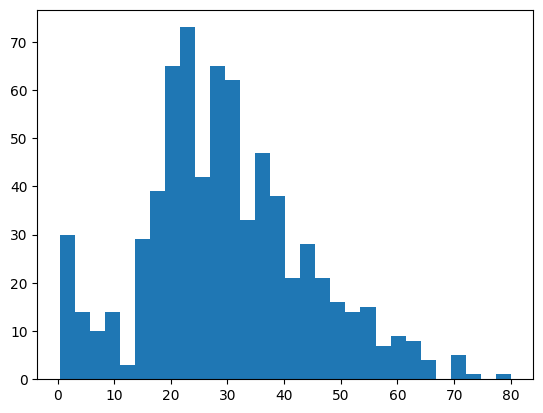

In [ ]:
plt.hist(df['Age'], bins=30)
plt.show()

In [ ]:
df.isna().sum()

,0
Pclass,0
Age,177
Sex,0
SibSp,0
Parch,0
Fare,0
Embarked,2
Survived,0


In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

/tmp/ipykernel_621/1219786438.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'] = df['Age'].fillna(df['Age'].mean(), inplace=True)
/tmp/ipykernel_621/1219786438.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

In [ ]:
df['Embarked'].unique()

array([None], dtype=object)

In [ ]:
df['Sex'] = df['Sex'].map({'male': 0, 'female':1})
df['Embarked']  = df['Embarked'].map({"S":0, 'C':1, 'Q':2})
display(df)

,Pclass,Age,Sex,SibSp,Parch,Fare,Embarked,Survived
0,3,None,0,1,0,7.2500,NaN,0
1,1,None,1,1,0,71.2833,NaN,1
2,3,None,1,0,0,7.9250,NaN,1
3,1,None,1,1,0,53.1000,NaN,1
4,3,None,0,0,0,8.0500,NaN,0
...,...,...,...,...,...,...,...,...
886,2,None,0,0,0,13.0000,NaN,0
887,1,None,1,0,0,30.0000,NaN,1
888,3,None,1,1,2,23.4500,NaN,0
889,1,None,0,0,0,30.0000,NaN,1


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(df[['Pclass', 'Age', 'Sex', 'SibSp', 'Parch', 'Fare', 'Embarked']], df['Survived'], test_size=0.2)

In [ ]:
dt = DecisionTreeClassifier()

In [ ]:
dt.fit(X_train, Y_train)
y_pred = dt.predict(X_test)

In [ ]:
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.86      0.83       111
           1       0.75      0.65      0.69        68

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179

